# Dominant Color Extraction - Part 1: Read the Image

First, we load an image with OpenCV and check its shape.

In [1]:
import matplotlib.pyplot as plt
import cv2

In [2]:
img = cv2.imread("lion.jpeg")

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(img.shape)

(350, 625, 3)


### What does the shape mean?

The output `(1530, 1224, 3)` means:

| Value | Meaning |
|---|---|
| `1530` | Height of the image (rows of pixels) |
| `1224` | Width of the image (columns of pixels) |
| `3` | Three color channels per pixel |

**Note:** OpenCV reads color channels in **BGR** order, not RGB. `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` converts the image to RGB so Matplotlib displays the correct colors.

## Display the image

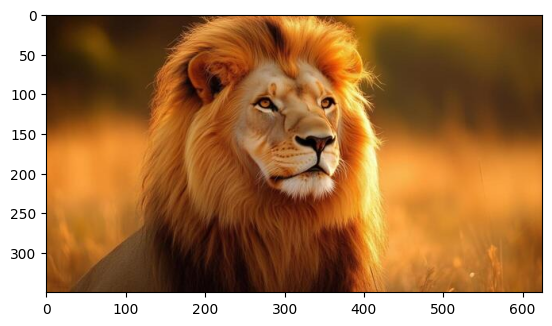

In [3]:
plt.imshow(img)
plt.show()

# Dominant Color Extraction - Part 2: K-Means on Pixels

**Goal:** Find the most dominant colors in the image using K-Means clustering.

## 1. Core idea

Each pixel has three color values: **Red, Green, Blue (RGB)**. For example, a pixel might be `[255, 100, 50]`.

We treat each pixel as a point in a 3D space:
- Feature 1 = Red
- Feature 2 = Green
- Feature 3 = Blue

K-Means groups pixels with similar colors together. The **centroid** of each cluster represents a **dominant color**.

## 2. Implementation steps

1. Read the image *(done above)*.
2. Resize it to reduce the number of pixels and speed up processing.
3. Reshape the image into a matrix of shape `(number_of_pixels, 3)`.
4. Apply K-Means with the desired number of clusters, $K$.
5. Extract the cluster centers.
6. Convert the center values into integers to represent RGB colors.

## Step 2: Resize the image

In [4]:
import numpy as np
from sklearn.cluster import KMeans

# Resize image (width=400, height=300) to speed up K-Means
image = cv2.resize(img, (400, 300))
print(image.shape)

(300, 400, 3)


## Step 3: Reshape pixels into rows of RGB values

In [5]:
X = image.reshape(-1, 3)
print(X.shape)

(120000, 3)


The `-1` in `reshape(-1, 3)` tells NumPy to calculate the number of pixels automatically.

## Step 4 & 5: Apply K-Means and extract cluster centers

In [12]:
# Extract 10 dominant colors
k = 10
model = KMeans(n_clusters=k, random_state=42, n_init=10)
model.fit(X)

centroids = model.cluster_centers_.astype(int)

print(centroids)

[[ 74  35  12]
 [190 113  38]
 [159  90  29]
 [242 218 135]
 [223 138  47]
 [ 95  55  20]
 [128  68  21]
 [180 136  94]
 [242 165  65]
 [ 39  16   7]]


## Step 6: Convert centers to integer RGB colors

In [13]:
print(centroids)
print(centroids.shape)

[[ 74  35  12]
 [190 113  38]
 [159  90  29]
 [242 218 135]
 [223 138  47]
 [ 95  55  20]
 [128  68  21]
 [180 136  94]
 [242 165  65]
 [ 39  16   7]]
(10, 3)


In [14]:
colors = np.array(centroids, dtype=np.uint8)
print(colors)

[[ 74  35  12]
 [190 113  38]
 [159  90  29]
 [242 218 135]
 [223 138  47]
 [ 95  55  20]
 [128  68  21]
 [180 136  94]
 [242 165  65]
 [ 39  16   7]]


## Display the dominant colors

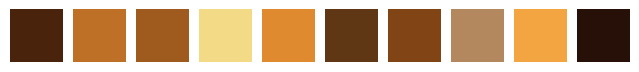

In [16]:
plt.figure(figsize=(8, 2))
for i, color in enumerate(colors):
    plt.subplot(1, k, i + 1)
    plt.axis("off")
    plt.imshow(np.full((100, 100, 3), color, dtype=np.uint8))
    # plt.title(str(color))
plt.show()

## 4. Understand the shapes

| Data | Shape | Meaning |
|---|---|---|
| Resized image | `(300, 400, 3)` | Height, width, RGB channels |
| `X` | `(120000, 3)` | 120,000 pixels, 3 features each |
| `colors` | `(4, 3)` | 4 dominant RGB colors |

**Note:** `cv2.resize` takes the size as `(width, height)`, but the resulting array shape is `(height, width, channels)`.

## 5. Why use `uint8`?

RGB values range from **0 to 255**. The NumPy type `np.uint8` stores integers in that range efficiently.

The cluster centers are initially floating-point averages, so we convert them to integers for displaying colors.

> **Remember:** Pixels are the data points, RGB values are the features, K-Means creates the clusters, and the centroids represent the dominant colors.

In [17]:
newImg = np.zeros((X.shape), dtype=np.uint8)
print(newImg.shape)

(120000, 3)


In [18]:
for i in range(newImg.shape[0]):
    newImg[i] = colors[model.labels_[i]]

(300, 400, 3)


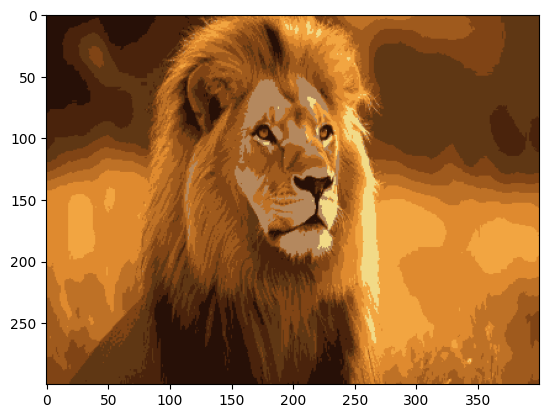

In [22]:
newImg = newImg.reshape(image.shape)
print(newImg.shape)
plt.imshow(newImg)

## 6. Turn the lion into a White Lion

Every pixel already belongs to one of the `k` clusters (`model.labels_`). So we can **recolor the whole image just by changing the palette** — no need to touch the pixels one by one.

Idea:
1. Compute the **brightness** (luminance) of each dominant color: `0.299*R + 0.587*G + 0.114*B`.
2. Map that brightness to a **white / cream** shade — bright golden fur becomes almost white, dark shadows become soft grey.
3. Rebuild the image using the new palette.


In [ ]:
# 1. Brightness of each dominant color (0 to 1)
brightness = (0.299 * colors[:, 0] + 0.587 * colors[:, 1] + 0.114 * colors[:, 2]) / 255

# 2. Map brightness to white/cream shades
#    darkest -> soft grey (~110), brightest -> near white (~255)
level = 110 + brightness / brightness.max() * 145
cream_tint = np.array([1.00, 0.98, 0.93])   # slight warm tint so it looks like fur, not paper
white_colors = np.clip(level[:, None] * cream_tint, 0, 255).astype(np.uint8)

print(white_colors)


In [ ]:
# Compare the original palette with the White Lion palette
plt.figure(figsize=(8, 2))
for i in range(k):
    plt.subplot(2, k, i + 1)
    plt.axis("off")
    plt.imshow(np.full((100, 100, 3), colors[i], dtype=np.uint8))
    plt.subplot(2, k, k + i + 1)
    plt.axis("off")
    plt.imshow(np.full((100, 100, 3), white_colors[i], dtype=np.uint8))
plt.show()


In [ ]:
# 3. Rebuild the image with the white palette (vectorized: palette[labels])
whiteLion = white_colors[model.labels_].reshape(image.shape)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Lion")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(whiteLion)
plt.title("White Lion")
plt.axis("off")
plt.show()


**Note:** `white_colors[model.labels_]` picks the new color for every pixel at once — it does the same job as the `for` loop above, but much faster.

Because the background grass shares the same golden colors as the lion, K-Means puts them in the same clusters, so the background turns pale too. Recoloring only the lion would need a mask (segmentation) to separate the lion from the background.
